## Causal Question

- **Unit:** one order (`order_id`)
- **Population:** completed e-commerce orders delivered to customers between January 2017 and August 2018 that have a recorded estimated delivery date, actual delivery date, and a customer review.
- **Treatment (T):** Delivery delay indicator ($T = 1$ if `order_delivered_customer_date > order_estimated_delivery_date`, else $0$).
- **Outcome (Y):** 
  - Primary: Binary indicator for good review (`is_good_review = 1` if `review_score >= 4`, else $0$).
  - Secondary: Continuous review star score (`review_score` from 1 to 5).
- **Estimand:** **ATT (Average Treatment Effect on the Treated)** — the causal impact of being late specifically among orders that were actually delivered late.
- **The decision it informs:** "If eliminating delivery delays increases the probability of a good review by at least 15 percentage points (or prevents a 30% drop in satisfaction) among late orders, Olist should invest in carrier SLA penalties, priority routing, or proactive customer delay communication."


1. Why review_score >= 4 (Binary) instead of Mean Star Score?
Non-linear Business Impact & Asymmetry: E-commerce ratings are heavily bi-modal (clustered at 1 and 5). Moving an angry customer from a 1-star to a 2-star rating does not materially save customer lifetime value or platform reputation—both are "bad reviews" that deter future purchases or churn the buyer. In practice, a score $\ge 4$ represents a satisfied customer who is likely to repurchase.
Interpretability as a Probability / Rate: A linear difference of -0.4 stars is abstract for business leadership. In contrast, an effect of -28 percentage points in good review rate directly translates into: $$\Delta \text{Satisfied Orders} = \Delta P(\text{Good Review}) \times \text{Volume}$$ This allows direct cost-benefit modeling against logistics intervention budgets.
Alignment with Prior Projects (North Star Metric): Churn, retention, and conversion metrics in earlier portfolio projects track binary states (churned vs. retained, positive vs. negative sentiment).

2. Why ATT (Average Treatment Effect on the Treated) over ATE?
ATE (Average Treatment Effect): Measures what would happen if every single order on Olist were delayed vs. on time.
ATT (Average Treatment Effect on the Treated): Measures the impact of the delay specifically on the orders that actually experienced a delay.
Why the business needs ATT: Logistics interventions (like automated expediting, carrier backup options, or buffer renegotiation) target the at-risk / delayed cohort, not orders that already arrive early or on time.

You want to answer: "For the orders that suffered late delivery, how much customer satisfaction did we lose because of the delay itself, rather than other factors (e.g., poor product quality, slow seller dispatch)?"

That is precisely the ATT.

In [1]:
import dowhy, duckdb, pandas as pd, statsmodels, networkx
print("dowhy", dowhy.__version__, "| duckdb", duckdb.__version__,
      "| pandas", pd.__version__, "| statsmodels", statsmodels.__version__)

dowhy 0.8 | duckdb 1.5.3 | pandas 3.0.1 | statsmodels 0.15.0


Trap 1: Promised Delivery Days
Role: Confounder (must be controlled for).
Explanation: Olist estimates promised delivery days upfront based on geography and postal zones.
Higher promised days $\rightarrow$ Larger buffer $\rightarrow$ Decreases the probability of being late ($T = 1$).
Higher promised days $\rightarrow$ Customer anticipates waiting weeks $\rightarrow$ Directly lowers baseline satisfaction ($Y$), independent of lateness.
Since it causally points to both $T$ and $Y$ ($T \leftarrow \text{Promise} \rightarrow Y$), it is a textbook backdoor path / confounder.

Trap 2: Actual Delivery Days
Role: Deterministic component of $T$ / Mediator (Do NOT control for primary estimand).
Explanation: $T = \mathbb{I}(\text{Actual Delivery Days} > \text{Promised Delivery Days})$.
If you adjust for Actual Delivery Days in your regression: you hold actual transit time fixed (e.g., exactly 10 days).
Comparing a late order ($T=1$) and an on-time order ($T=0$) that both took 10 days means the late order was promised 8 days, while the on-time order was promised 12 days.
The primary question: "What is the cost of delivering late to a customer?"
Conditioning on actual days asks: "Holding delivery time constant, what is the effect of having set an overly optimistic delivery estimate?" (This answers the psychological expectations gap in Q7, but ruins the primary ATE).

Trap 3: Whether the Customer Wrote a Review
Role: Collider / Selection Bias.
Explanation: In the DAG: $T \rightarrow \text{Review Written} \leftarrow Y_{\text{latent}}$.
A late delivery triggers strong negative emotion, motivating the buyer to leave a review.
Unobserved quality / latent satisfaction also dictates whether someone bothers to review.
Because we can only measure review score $Y$ when $\text{Review Written} = 1$, we condition on a post-treatment outcome.
Conditioning on a descendant of a collider introduces selection bias (collider stratification bias), making on-time and late cohorts non-comparable unless review completion rates are addressed (e.g., through sensitivity bounds or propensity to review weighting).






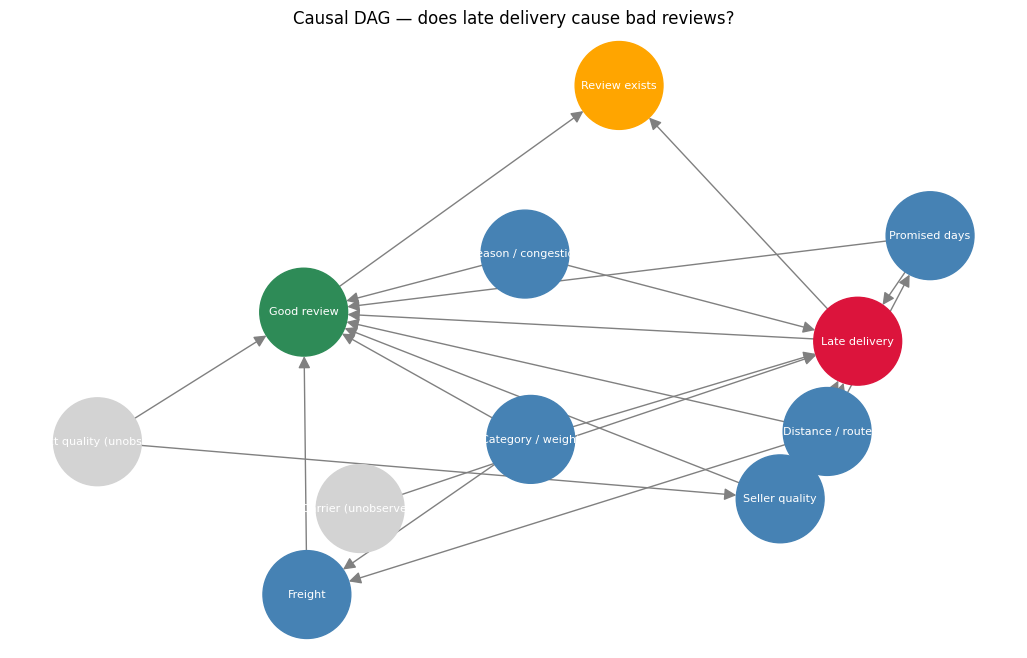

In [3]:
import networkx as nx
import matplotlib.pyplot as plt

edges = [
    ("Distance / route", "Promised days"), ("Distance / route", "Freight"),
    ("Distance / route", "Late delivery"), ("Distance / route", "Good review"),
    ("Promised days", "Late delivery"), ("Promised days", "Good review"),
    ("Seller quality", "Late delivery"), ("Seller quality", "Good review"),
    ("Category / weight", "Freight"), ("Category / weight", "Late delivery"),
    ("Category / weight", "Good review"),
    ("Freight", "Good review"),
    ("Season / congestion", "Late delivery"), ("Season / congestion", "Good review"),
    ("Carrier (unobserved)", "Late delivery"),
    ("Product quality (unobserved)", "Good review"),
    ("Product quality (unobserved)", "Seller quality"),
    ("Late delivery", "Good review"),
    ("Late delivery", "Review exists"), ("Good review", "Review exists"),
]
# ← this is a STARTING POINT. Add, remove and reverse edges until it matches YOUR table in 3.1.

G = nx.DiGraph(edges)
role = {"Late delivery": "crimson", "Good review": "seagreen", "Review exists": "orange"}
colors = [role.get(n, "lightgray" if "unobserved" in n else "steelblue") for n in G.nodes]

fig, ax = plt.subplots(figsize=(13, 8))
pos = nx.spring_layout(G, seed=4, k=1.2)   # or write a dict of (x, y) positions by hand — usually prettier
nx.draw_networkx(G, pos, ax=ax, node_color=colors, node_size=4000, font_size=8,
                 font_color="white", arrowsize=18, edge_color="gray")
ax.set_title("Causal DAG — does late delivery cause bad reviews?")
ax.axis("off")
plt.savefig("../reports/dag.png", dpi=150, bbox_inches="tight")
plt.show()

Pre-register the analysis

**My prior:** "Before seeing data, I expect the adjusted effect to be about 60-70% of the naive
  gap, because part of the naive penalty comes from bad products or long-distance shipments
  rather than delivery delay itself."